# Formatting changes to reference pathway evaluation table - August 14, 2017
Rename the pathways, add a derived column, filter the algorithms.  Updated from the June 24, 2016 version to add FunChisq

In [1]:
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

eval_dir = os.path.join('..','..','evaluation','2017-01-10-DBN-TXN-FUNCHISQ-TPS-network-reference-comparisons-fixed')
in_file = os.path.join(eval_dir, 'table.tsv')
out_file = os.path.join(eval_dir, 'table-formatted.tsv')

## Read the input table
Use different header names

In [2]:
header = ['Reference', 'Method original', 'Reference size', 'Network size', 'Undirected edge matches',
          'Undirected precision', 'Undirected recall', 'Directed predictions', 'Directed edge matches',
          'Correct directions', 'Incorrect directions', 'Unevaluated directions']
eval_df = pd.read_csv(in_file, sep='\t', names = header)
print 'Loaded %d evaluation rows' % len(eval_df)
assert len(eval_df) == 15 * 12
eval_df.head()

Loaded 180 evaluation rows


,Reference,Method original,Reference size,Network size,Undirected edge matches,Undirected precision,Undirected recall,Directed predictions,Directed edge matches,Correct directions,Incorrect directions,Unevaluated directions
0,biocarta-edges.tsv,TXN-1F-directed.sif,1750,555,61,0.109910,0.034857,555,61,26,13,22
1,biocarta-edges.tsv,TXN-1F-undirected-topo-kinsub-output.sif,1750,524,59,0.112595,0.033714,234,26,18,2,6
2,biocarta-edges.tsv,TXN-ALL-directed.sif,1750,1073,93,0.086673,0.053143,1073,93,37,19,37
3,biocarta-edges.tsv,DBN,1750,572,9,0.015734,0.005143,557,9,4,2,3
4,biocarta-edges.tsv,TXN-1F-undirected-topo-kinsub-temp-output.sif,1750,519,59,0.113680,0.033714,246,26,18,2,6


## Test derived columns

In [3]:
for (index, row) in eval_df.iterrows():
    assert row['Directed edge matches'] == row['Correct directions'] + row['Incorrect directions'] + row['Unevaluated directions']
    assert abs(row['Undirected precision'] - (float(row['Undirected edge matches'])/row['Network size'])) < 0.0001, row
    assert abs(row['Undirected recall'] - (float(row['Undirected edge matches'])/row['Reference size'])) < 0.0001, row
    assert row['Directed predictions'] <= row['Network size']

## Rename pathways, rename methods, ignore methods
Drop the Panther evaluation.  We did not use it when evaluating phosphorylation overlap and it does not add any new information to the comparison.

Use the same pathway names used in the phoshorylation overlap figures.  Rename the methods.  Only the three primary methods are discussed in the paper.

Use the top 1000 edge version of FunChisq because after collapsing directed edges it is more similar in size to the other networks.

In [4]:
# Map the method names to human-readable names and drop all methods not in this map
method_names = {'TXN-ALL-directed.sif':'TimeXNet',
                'DBN':'DBN',
                'TPS.sif':'TPS',
                'funchisq-1000.sif':'FunChisq'}
eval_df = eval_df.loc[eval_df['Method original'].isin(method_names.keys())]
print '%d methods' % len(method_names)

# Rename the method column
eval_df.insert(0, 'Method', eval_df.apply(lambda row: method_names[row['Method original']], axis=1))
eval_df = eval_df.drop('Method original', axis=1)

# Remove the Panther rows
eval_df = eval_df.loc[eval_df['Reference'] != 'panther-edges.tsv']

# Map the pathway names to human-readable names
pathway_names = {'kegg-4012':'KEGG ErbB', # http://www.genome.jp/kegg-bin/show_pathway?hsa04012
                    'kegg-4010':'KEGG MAPK', # http://www.genome.jp/kegg-bin/show_pathway?hsa04010
                    'layek':'Layek et al.', # http://bioinformatics.oxfordjournals.org/content/27/4/548/F4.large.jpg
                    'reactome-reactome-egfr':'Reactome EGFR',
                    'biocarta-egfr':'BioCarta EGF', # http://www.biocarta.com/pathfiles/h_egfpathway.asp
                    'science-signaling-egfr':'Science Signaling EGFR', # Not longer available online
                    'cellmap-commons-egfr':'Cancer Cell Map EGFR1', # http://www.pathwaycommons.org/pc/dbSnapshot.do?snapshot_id=8
                    'nci-nature-egfr':'PID ErbB1', # http://pid.nci.nih.gov/search/pathway_landing.shtml?pathway_id=200101&source=NATURE&what=graphic&jpg=on
                    'biocarta':'All BioCarta',
                    'reactome-reactome':'All Reactome',
                    'nci-nature':'All PID'}
print '%d reference pathways' % len(pathway_names)

# Rename the reference pathway column
eval_df.insert(0, 'Reference pathway', eval_df.apply(lambda row: pathway_names[row['Reference'].replace('-edges.tsv', '')], axis=1))
eval_df = eval_df.drop('Reference', axis=1)

# Confirm the expected number of rows remain
assert len(eval_df) == len(method_names) * len(pathway_names)

eval_df.head()

4 methods
11 reference pathways


,Reference pathway,Method,Reference size,Network size,Undirected edge matches,Undirected precision,Undirected recall,Directed predictions,Directed edge matches,Correct directions,Incorrect directions,Unevaluated directions
2,All BioCarta,TimeXNet,1750,1073,93,0.086673,0.053143,1073,93,37,19,37
3,All BioCarta,DBN,1750,572,9,0.015734,0.005143,557,9,4,2,3
5,All BioCarta,FunChisq,1750,630,6,0.009524,0.003429,260,3,0,0,3
10,All BioCarta,TPS,1750,413,12,0.029056,0.006857,202,5,3,0,2
17,BioCarta EGF,TimeXNet,18,1073,4,0.003728,0.222222,1073,4,3,0,1


## Helper function for directed precision

In [5]:
def precision(correct, incorrect):
    total = correct + incorrect
    if total == 0:
        return 'N/A'
    else:
        return float(correct)/total

##  Add derived columns
Normalize the number of confirmed and wrong orientations by the number of oriented predictions.  This makes it easier to see the rate at which different methods make correct and incorrect direction predictions.  Add the directed precision.  It is hard to determine directed recall.

In [6]:
eval_df['Directed precision'] = eval_df.apply(lambda row: precision(row['Correct directions'], row['Incorrect directions']), axis=1)
eval_df['Correct directions per 1000'] = eval_df.apply(lambda row: float(row['Correct directions'])*1000/row['Directed predictions'], axis=1)
eval_df['Incorrect directions per 1000'] = eval_df.apply(lambda row: float(row['Incorrect directions'])*1000/row['Directed predictions'], axis=1)

eval_df.head()

,Reference pathway,Method,Reference size,Network size,Undirected edge matches,Undirected precision,Undirected recall,Directed predictions,Directed edge matches,Correct directions,Incorrect directions,Unevaluated directions,Directed precision,Correct directions per 1000,Incorrect directions per 1000
2,All BioCarta,TimeXNet,1750,1073,93,0.086673,0.053143,1073,93,37,19,37,0.660714,34.482759,17.707363
3,All BioCarta,DBN,1750,572,9,0.015734,0.005143,557,9,4,2,3,0.666667,7.181329,3.590664
5,All BioCarta,FunChisq,1750,630,6,0.009524,0.003429,260,3,0,0,3,N/A,0.000000,0.000000
10,All BioCarta,TPS,1750,413,12,0.029056,0.006857,202,5,3,0,2,1,14.851485,0.000000
17,BioCarta EGF,TimeXNet,18,1073,4,0.003728,0.222222,1073,4,3,0,1,1,2.795899,0.000000


## Sort the table rows
Smallest reference pathways first.  TPS first.  Sorting is case-sensitive so temporarily add a new column for sorting the methods.

In [7]:
eval_df['Method sort'] = eval_df.apply(lambda row: row['Method'].upper(), axis=1)
eval_df = eval_df.sort(['Reference size','Method sort'], ascending=[True,False])
eval_df = eval_df.drop('Method sort', axis=1)
eval_df.head()

C:\Program Files\Anaconda\lib\site-packages\IPython\kernel\__main__.py:2: FutureWarning: sort(columns=....) is deprecated, use sort_values(by=.....)
  from IPython.kernel.zmq import kernelapp as app


,Reference pathway,Method,Reference size,Network size,Undirected edge matches,Undirected precision,Undirected recall,Directed predictions,Directed edge matches,Correct directions,Incorrect directions,Unevaluated directions,Directed precision,Correct directions per 1000,Incorrect directions per 1000
25,BioCarta EGF,TPS,18,413,2,0.004843,0.111111,202,1,0,0,1,N/A,0.000000,0.0
17,BioCarta EGF,TimeXNet,18,1073,4,0.003728,0.222222,1073,4,3,0,1,1,2.795899,0.0
20,BioCarta EGF,FunChisq,18,630,3,0.004762,0.166667,260,1,0,0,1,N/A,0.000000,0.0
18,BioCarta EGF,DBN,18,572,2,0.003497,0.111111,557,2,2,0,0,1,3.590664,0.0
115,PID ErbB1,TPS,44,413,8,0.019370,0.181818,202,4,1,0,3,1,4.950495,0.0


## Visualize the normalized correct and incorrect predictions
Could clean this up to include as a supplementary figure but not planning to currently.  Temporarily include the difference between these two values.

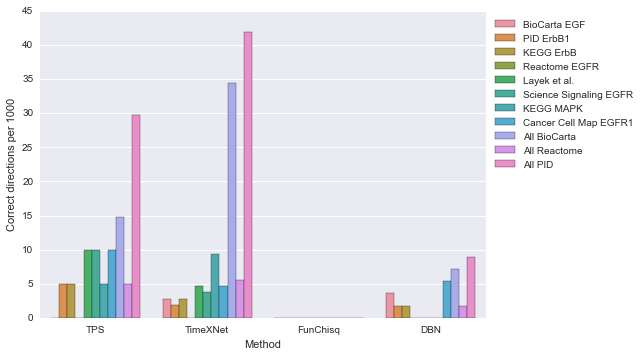

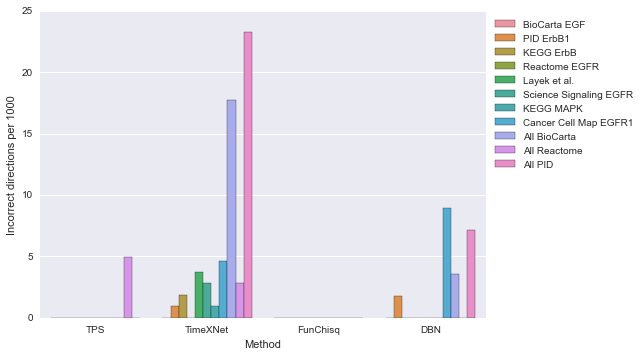

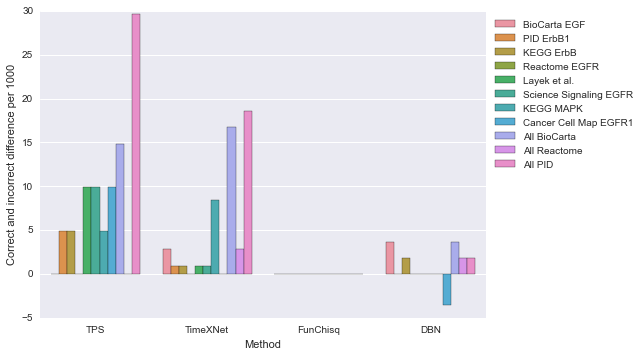

In [8]:
ax = sns.barplot(x='Method', y='Correct directions per 1000', hue='Reference pathway', data=eval_df);
ax.set_ylabel('Correct directions per 1000');
ax.legend(loc='upper left', bbox_to_anchor=(1,1));

plt.figure();
ax = sns.barplot(x='Method', y='Incorrect directions per 1000', hue='Reference pathway', data=eval_df);
ax.set_ylabel('Incorrect directions per 1000');
ax.legend(loc='upper left', bbox_to_anchor=(1,1));

eval_df['Correct and incorrect difference per 1000'] = eval_df.apply(lambda row: row['Correct directions per 1000']- row['Incorrect directions per 1000'], axis=1)
plt.figure();
ax = sns.barplot(x='Method', y='Correct and incorrect difference per 1000', hue='Reference pathway', data=eval_df);
ax.set_ylabel('Correct and incorrect difference per 1000');
ax.legend(loc='upper left', bbox_to_anchor=(1,1));
eval_df = eval_df.drop('Correct and incorrect difference per 1000', axis=1)

Same figure grouped by pathway instead of method.  TPS does better than TimeXNet on many pathways.

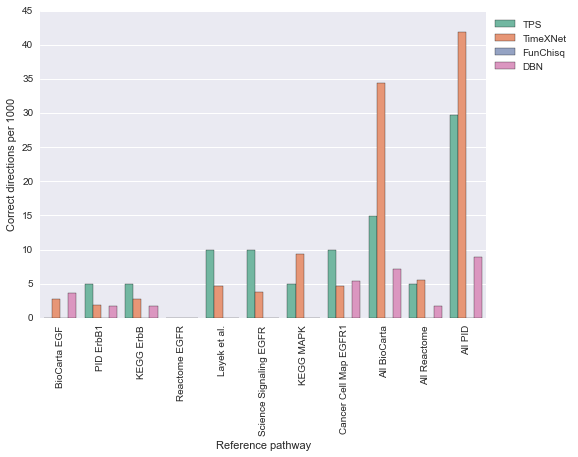

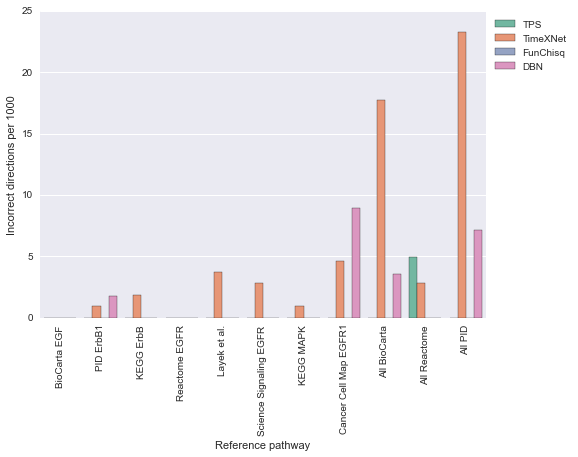

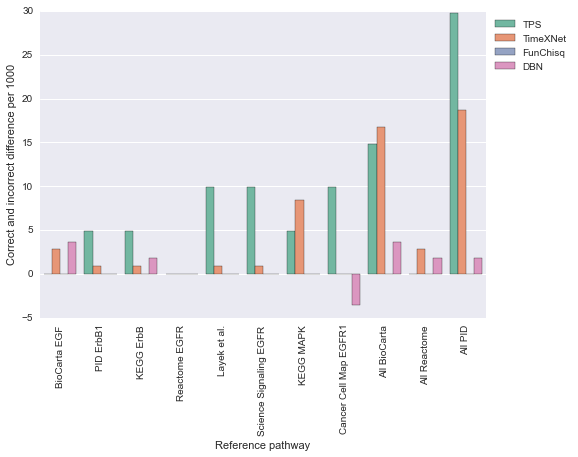

In [9]:
pal = sns.color_palette('Set2', 4)

ax = sns.barplot(x='Reference pathway', y='Correct directions per 1000', hue='Method', data=eval_df, palette=pal);
ax.set_ylabel('Correct directions per 1000');
ax.legend(loc='upper left', bbox_to_anchor=(1,1));
plt.xticks(rotation=90);

plt.figure();
ax = sns.barplot(x='Reference pathway', y='Incorrect directions per 1000', hue='Method', data=eval_df, palette=pal);
ax.set_ylabel('Incorrect directions per 1000');
ax.legend(loc='upper left', bbox_to_anchor=(1,1));
plt.xticks(rotation=90);

eval_df['Correct and incorrect difference per 1000'] = eval_df.apply(lambda row: row['Correct directions per 1000']- row['Incorrect directions per 1000'], axis=1)
plt.figure();
ax = sns.barplot(x='Reference pathway', y='Correct and incorrect difference per 1000', hue='Method', data=eval_df, palette=pal);
ax.set_ylabel('Correct and incorrect difference per 1000');
ax.legend(loc='upper left', bbox_to_anchor=(1,1));
eval_df = eval_df.drop('Correct and incorrect difference per 1000', axis=1)
plt.xticks(rotation=90);

## Write the updated table

In [10]:
eval_df.to_csv(out_file, sep='\t', index=False)
print 'Wrote %s' % out_file

Wrote ..\..\evaluation\2017-01-10-DBN-TXN-FUNCHISQ-TPS-network-reference-comparisons-fixed\table-formatted.tsv
